In [1]:
# !pip install catboost pandas numpy scikit-learn matplotlib openpyxl      # run once if needed
import re, os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import attrition_core as core
from attrition_core import (load_data, guess_target, encode_target, describe_dataset, prepare_xy,
                            make_catboost, DEFAULT_CB_PARAMS, random_search_catboost, tune_knn_k,
                            compare_models, importance_table, catboost_shap, auto_insights,
                            best_f1_threshold, predict_new, make_sample_data)
pd.set_option("display.max_columns", 50)
from IPython.display import HTML, display
def show_anim(a):
    # shows an animation made by core.animate_*  (press play, drag the slider, change speed)
    display(HTML(a[0]))

## 1. Dataset understanding
Load the data, find the target column, and describe features, types, missing values and class balance.

In [2]:
DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition.csv"   # <-- put YOUR file here (.csv / .xlsx)
# Google Colab:  from google.colab import files; up = files.upload(); DATA_PATH = list(up)[0]

if os.path.exists(DATA_PATH):
    df = load_data(DATA_PATH)
    print("Loaded:", DATA_PATH)
else:
    df = make_sample_data()
    print("WARNING: file not found -> using SYNTHETIC demo data. Replace DATA_PATH with your real dataset.")

TARGET = guess_target(df)          # change manually if the guess is wrong, e.g. TARGET = "Left"
print(f"Rows: {df.shape[0]}   Columns: {df.shape[1]}   Target column: '{TARGET}'")
df.head()

Rows: 1470   Columns: 32   Target column: 'Attrition'


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,58,Travel_Rarely,819,Human Resources,27,1,Life Sciences,1,1,2,Female,1,5,Laboratory Technician,2.0,Married,19197.0,7,Y,No,19,3,80,0,39,1,2,24,20,0,20,No
1,44,Travel_Rarely,937,Sales,23,1,Medical,1,2,1,Female,2,3,Manager,1.0,Divorced,12133.0,9,Y,Yes,16,3,80,0,23,4,3,3,0,2,0,No
2,47,Travel_Rarely,932,Research & Development,13,2,Life Sciences,1,3,2,Male,2,3,Healthcare Representative,1.0,Married,11217.0,0,Y,No,16,3,80,3,22,1,4,3,0,4,2,No
3,56,Travel_Rarely,1275,Research & Development,11,5,Life Sciences,1,4,2,Female,4,5,Sales Representative,1.0,Married,NaN,6,Y,No,14,3,80,3,34,0,3,15,13,3,15,No
4,42,Travel_Rarely,999,Sales,21,1,Marketing,1,5,2,Female,1,4,Healthcare Representative,2.0,Divorced,14542.0,7,Y,No,19,3,80,1,20,1,4,4,1,5,1,No


In [3]:
summary = describe_dataset(df, TARGET)
summary

,feature,role,dtype,type,unique,missing_%,example
0,Age,feature,int64,numeric,43,0.00,58
1,BusinessTravel,feature,object,categorical,3,0.00,Travel_Rarely
2,DailyRate,feature,int64,numeric,902,0.00,819
3,Department,feature,object,categorical,3,0.48,Human Resources
4,DistanceFromHome,feature,int64,numeric,29,0.00,27
5,Education,feature,int64,numeric,5,0.00,1
6,EducationField,feature,object,categorical,5,0.00,Life Sciences
7,EmployeeCount,feature,int64,numeric,1,0.00,1
8,EmployeeNumber,feature,int64,numeric,1470,0.00,1
9,EnvironmentSatisfaction,feature,int64,numeric,4,0.00,2


Attrition rate: 0.1735
Numeric features    : 23
Categorical features: 8
Total missing cells : 28


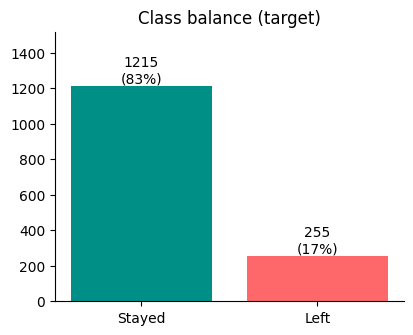

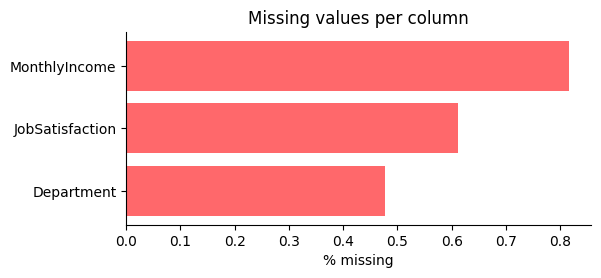

In [4]:
y_all = encode_target(df[TARGET])
print("Attrition rate:", round(y_all.mean(), 4))
print("Numeric features    :", ((summary.type == "numeric") & (summary.role != "TARGET")).sum())
print("Categorical features:", ((summary.type == "categorical") & (summary.role != "TARGET")).sum())
print("Total missing cells :", int(df.isna().sum().sum()))
fig = core.plot_class_balance(y_all); plt.show()
fig = core.plot_missing(df); plt.show()

**Reading the output.** The target is imbalanced: far fewer employees leave than stay. Therefore *accuracy alone is misleading* (predicting "nobody leaves" already scores high); we focus on **recall, F1 and ROC-AUC**, and use class weights.

## 2. Data preprocessing
Every step is performed inside the `Preprocessor` class below and is **fitted on the training split only** (so no information from the test set leaks into training).

| Step | What | Why |
|---|---|---|
| Drop columns | constant columns, ID-like columns, >60 % missing | carry no predictive information (e.g. `EmployeeNumber`) and can cause over-fitting |
| Missing values | numeric -> median, categorical -> `"Missing"` | the median is robust to outliers; a `"Missing"` level lets the model learn if missingness itself is informative |
| Outliers | IQR capping (winsorising) on continuous columns | extreme values distort distance-based models (KNN) and linear models |
| Encoding | CatBoost: raw text categories (native ordered target encoding); other models: one-hot | CatBoost handles categories better than one-hot; KNN / LogReg need numbers |
| Scaling | z-score (for KNN, LogReg, manual GBM) | puts features on one scale. Trees (CatBoost, RF) do not need it |

In [5]:
class Preprocessor:
    """
    Steps (each one is logged in `log_` so it can be explained in the report):
      1. Drop useless columns  : constant, ID-like, >60 % missing
      2. Missing values        : numeric -> median, categorical -> 'Missing'
      3. Outlier treatment     : IQR capping (winsorising) on continuous columns
      4. Categorical handling  : kept as text for CatBoost (native encoding);
                                 one-hot encoded for the other models
      5. Scaling               : z-score for the models that need it (KNN, LogReg, manual GBM)
    """

    def __init__(self, cap_outliers=True, iqr_k=1.5, max_missing=0.6, id_ratio=0.95):
        self.cap_outliers, self.iqr_k = cap_outliers, iqr_k
        self.max_missing, self.id_ratio = max_missing, id_ratio

    @staticmethod
    def _is_num(s):
        return pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)

    def fit(self, X):
        n = len(X)
        self.log_, self.dropped_ = [], {}
        for c in X.columns:
            s = X[c]
            nun = s.nunique(dropna=True)
            int_like = (not self._is_num(s)) or bool((s.dropna() % 1 == 0).all())
            name_hint = bool(re.search(r"(^|_)id$|number$|^id_", c.lower()))
            if s.isna().mean() > self.max_missing:
                self.dropped_[c] = "more than 60% missing"
            elif nun <= 1:
                self.dropped_[c] = "constant (no information)"
            elif n > 20 and int_like and (nun / n > self.id_ratio or (name_hint and nun / n > 0.5)):
                self.dropped_[c] = "ID-like (almost every value unique)"
        keep = [c for c in X.columns if c not in self.dropped_]
        self.feature_order_ = keep
        self.num_cols_ = [c for c in keep if self._is_num(X[c])]
        self.cat_cols_ = [c for c in keep if c not in self.num_cols_]
        if self.dropped_:
            self.log_.append("Dropped columns: " + "; ".join(f"{k} ({v})" for k, v in self.dropped_.items()))

        # missing values
        self.medians_ = X[self.num_cols_].median()
        miss = X[keep].isna().sum()
        miss = miss[miss > 0]
        self.log_.append("Missing values -> numeric: median, categorical: 'Missing'. Affected: "
                         + (", ".join(f"{k} ({v})" for k, v in miss.items()) if len(miss) else "none"))

        # outliers (only continuous-like columns: > 10 distinct values)
        self.bounds_ = {}
        outl = {}
        for c in self.num_cols_:
            s = X[c].fillna(self.medians_[c])
            q1, q3 = s.quantile([0.25, 0.75])
            iqr = q3 - q1
            if self.cap_outliers and iqr > 0 and s.nunique() > 10:
                lo, hi = q1 - self.iqr_k * iqr, q3 + self.iqr_k * iqr
                self.bounds_[c] = (lo, hi)
                k = int(((s < lo) | (s > hi)).sum())
                if k:
                    outl[c] = k
        self.log_.append("Outliers capped with the IQR rule (1.5xIQR): "
                         + (", ".join(f"{k} ({v})" for k, v in outl.items()) if outl else "none found"))

        # categorical levels (for one-hot)
        self.levels_ = {}
        for c in self.cat_cols_:
            s = X[c].astype("object").where(X[c].notna(), "Missing").astype(str)
            self.levels_[c] = list(s.value_counts().index[:30])
        self.log_.append(f"Categorical columns ({len(self.cat_cols_)}): {self.cat_cols_}")
        self.log_.append(f"Numeric columns ({len(self.num_cols_)}): {self.num_cols_}")

        # scaling stats
        Z = self._clean(X)
        self.mean_ = Z[self.num_cols_].mean()
        self.std_ = Z[self.num_cols_].std().replace(0, 1).fillna(1)
        return self

    def _clean(self, X):
        out = {}
        for c in self.feature_order_:
            if c in self.num_cols_:
                s = pd.to_numeric(X[c], errors="coerce") if c in X else pd.Series(np.nan, index=X.index)
                s = s.fillna(self.medians_[c])
                if c in self.bounds_:
                    s = s.clip(*self.bounds_[c])
                out[c] = s
            else:
                if c in X:
                    s = X[c].astype("object").where(X[c].notna(), "Missing").astype(str)
                else:
                    s = pd.Series("Missing", index=X.index)
                out[c] = s
        return pd.DataFrame(out, index=X.index)

    def transform_cb(self, X):
        """Clean (not scaled) frame with categoricals kept as text -> for CatBoost."""
        return self._clean(X)

    def transform_num(self, X):
        """Fully numeric, scaled, one-hot matrix -> for KNN / LogReg / RF / manual GBM."""
        Z = self._clean(X)
        parts = [((Z[self.num_cols_] - self.mean_) / self.std_)]
        for c in self.cat_cols_:
            parts.append(pd.DataFrame({f"{c}={lvl}": (Z[c] == lvl).astype(float) for lvl in self.levels_[c]},
                                      index=Z.index))
        return pd.concat(parts, axis=1)


# make the saved model loadable outside this notebook (e.g. from app.py): same class, importable location
Preprocessor.__module__ = "attrition_core"
core.Preprocessor = Preprocessor

In [6]:
# --- split first (stratified keeps the same % of leavers in train and test) ---
X, y, n_dups = prepare_xy(df, TARGET)
print("Duplicate rows removed:", n_dups)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

pre = Preprocessor().fit(Xtr)
for line in pre.log_:
    print("-", line)

Xtr_cb, Xte_cb   = pre.transform_cb(Xtr),  pre.transform_cb(Xte)    # for CatBoost
Xtr_num, Xte_num = pre.transform_num(Xtr), pre.transform_num(Xte)   # for the other models
print("\nTrain:", Xtr_cb.shape, " Test:", Xte_cb.shape, " One-hot matrix:", Xtr_num.shape)
print("Leavers in train / test:", round(ytr.mean(), 3), "/", round(yte.mean(), 3))

Duplicate rows removed: 0
- Dropped columns: EmployeeCount (constant (no information)); EmployeeNumber (ID-like (almost every value unique)); Over18 (constant (no information)); StandardHours (constant (no information))
- Missing values -> numeric: median, categorical: 'Missing'. Affected: Department (7), JobSatisfaction (7), MonthlyIncome (10)
- Outliers capped with the IQR rule (1.5xIQR): YearsAtCompany (23)
- Categorical columns (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
- Numeric columns (20): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Train: (1176, 27)  Test: (294, 27)  One-hot ma

In [7]:
# Before vs after: missing values and a continuous column
print("Missing cells before:", int(Xtr.isna().sum().sum()), " after:", int(Xtr_cb.isna().sum().sum()))

Missing cells before: 24  after: 0


## 3. Algorithm implemented from scratch - Gradient Boosting with decision stumps
CatBoost is a *gradient boosting* algorithm. To show that we understand what happens inside it, we implement the core idea ourselves with NumPy:

1. start with a constant prediction (log-odds of the leaver rate);
2. in each round compute, for every employee, the **gradient** `g = p - y` and **hessian** `h = p(1-p)` of the log-loss;
3. find the single best split (feature + threshold) using the gain `GL²/(HL+λ) + GR²/(HR+λ) − G²/(H+λ)`;
4. set the two leaf values by a Newton step `-G/(H+λ)`;
5. add them (scaled by the learning rate) to the model and repeat.

(CatBoost does the same with deeper *symmetric* trees, ordered boosting and ordered target statistics for categories.)

In [8]:
class ManualGradientBoosting:
    """
    Gradient boosting for binary classification, written from scratch with NumPy.
    This is the same idea CatBoost uses (add small trees one after another, each one
    correcting the mistakes of the ensemble so far) in its simplest form.

    Weak learner : decision stump (a tree with ONE split).
    Loss         : logistic loss (log-loss).
    Per round    : 1. p = sigmoid(F)                       current probabilities
                   2. g = p - y ,  h = p(1 - p)            gradient & hessian of log-loss
                   3. for every feature/threshold:
                          gain = GL^2/(HL+lam) + GR^2/(HR+lam) - G^2/(H+lam)
                   4. pick best split; leaf value = -G / (H + lam)    (Newton step)
                   5. F += learning_rate * leaf value
    """

    def __init__(self, n_estimators=100, learning_rate=0.1, max_bins=16, reg_lambda=1.0):
        self.n_estimators, self.learning_rate = n_estimators, learning_rate
        self.max_bins, self.reg_lambda = max_bins, reg_lambda

    @staticmethod
    def _sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        lam = self.reg_lambda
        qs = np.linspace(0, 1, self.max_bins + 2)[1:-1]
        self.thresholds_ = [np.unique(np.quantile(X[:, j], qs)) for j in range(d)]
        bins = np.column_stack([np.digitize(X[:, j], self.thresholds_[j], right=True) for j in range(d)])

        p0 = np.clip(y.mean(), 1e-6, 1 - 1e-6)
        self.base_ = np.log(p0 / (1 - p0))
        F = np.full(n, self.base_)
        self.stumps_, self.loss_history_ = [], []
        self.gain_importance_ = np.zeros(d)

        for _ in range(self.n_estimators):
            p = self._sigmoid(F)
            g, h = p - y, p * (1 - p)
            G, H = g.sum(), h.sum()
            parent = G * G / (H + lam)
            best = (0.0, None, None)
            for j in range(d):
                k = len(self.thresholds_[j])
                if k == 0:
                    continue
                gb = np.bincount(bins[:, j], weights=g, minlength=k + 1)
                hb = np.bincount(bins[:, j], weights=h, minlength=k + 1)
                GL, HL = np.cumsum(gb)[:k], np.cumsum(hb)[:k]      # left = x <= threshold
                GR, HR = G - GL, H - HL
                gain = GL ** 2 / (HL + lam) + GR ** 2 / (HR + lam) - parent
                gain[(HL < 1e-6) | (HR < 1e-6)] = -np.inf
                b = int(np.argmax(gain))
                if gain[b] > best[0]:
                    best = (gain[b], j, b)
            gain, j, b = best
            if j is None:
                break
            t = self.thresholds_[j][b]
            left = X[:, j] <= t
            GL, HL = g[left].sum(), h[left].sum()
            lv = -GL / (HL + lam)
            rv = -(G - GL) / (H - HL + lam)
            self.stumps_.append((j, t, lv, rv))
            self.gain_importance_[j] += gain
            F += self.learning_rate * np.where(left, lv, rv)
            p = self._sigmoid(F)
            self.loss_history_.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        F = np.full(len(X), self.base_)
        for j, t, lv, rv in self.stumps_:
            F += self.learning_rate * np.where(X[:, j] <= t, lv, rv)
        return F

    def staged_decision(self, X, rounds):
        """Raw scores after each boosting round listed in `rounds` (1-based). Used for the animation."""
        X = np.asarray(X, dtype=float)
        F, want, out = np.full(len(X), self.base_), set(rounds), {}
        for r, (j, t, lv, rv) in enumerate(self.stumps_, 1):
            F = F + self.learning_rate * np.where(X[:, j] <= t, lv, rv)
            if r in want:
                out[r] = F.copy()
        return out

    def predict_proba(self, X):
        p = self._sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

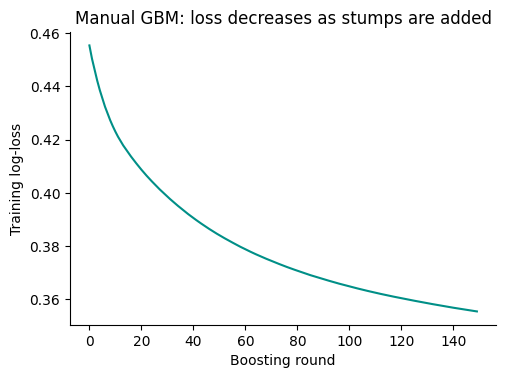

First 8 stumps chosen by the algorithm (it picks the most informative split first):
  split on Age                                 <=   -0.094   leaf values: left +0.67 / right -0.64
  split on JobLevel                            <=   -0.045   leaf values: left +0.51 / right -0.71
  split on JobLevel                            <=   -0.045   leaf values: left +0.45 / right -0.67
  split on OverTime=Yes                        <=    0.000   leaf values: left -0.33 / right +0.89
  split on Age                                 <=   -0.094   leaf values: left +0.47 / right -0.56
  split on OverTime=No                         <=    0.000   leaf values: left +0.76 / right -0.31
  split on JobLevel                            <=   -0.045   leaf values: left +0.36 / right -0.61
  split on Age                                 <=   -0.094   leaf values: left +0.37 / right -0.50

Manual GBM test ROC-AUC: 0.84


In [9]:
gbm = ManualGradientBoosting(n_estimators=150, learning_rate=0.1).fit(Xtr_num.values, ytr.values)
fig = core.plot_loss_curve(gbm); plt.show()

print("First 8 stumps chosen by the algorithm (it picks the most informative split first):")
for j, t, lv, rv in gbm.stumps_[:8]:
    print(f"  split on {Xtr_num.columns[j]:35s} <= {t:8.3f}   leaf values: left {lv:+.2f} / right {rv:+.2f}")

p_gbm = gbm.predict_proba(Xte_num.values)[:, 1]
print("\nManual GBM test ROC-AUC:", round(roc_auc_score(yte, p_gbm), 4))

**Interpretation.** The loss falls every round, which shows boosting works: each stump corrects the errors of the previous ones. The first splits show which features the algorithm finds most useful.

**Animation - watch the from-scratch model learn.** Left: predicted probabilities of stayers (teal) and leavers (coral) on the test set. At round 1 everyone gets the same score; with every added stump the two groups drift apart. Right: the test ROC-AUC climbing as rounds are added. Press ▶ to play.

In [10]:
show_anim(core.animate_boosting(gbm, Xte_num.values, yte))

## 4. Algorithm application - CatBoost
CatBoost receives the categorical columns as **text** (`cat_features=`), so no manual one-hot encoding is needed.
`auto_class_weights="Balanced"` gives leavers a higher weight to counter the class imbalance.

In [11]:
cat_cols = pre.cat_cols_
cb_base = make_catboost(DEFAULT_CB_PARAMS, cat_cols).fit(Xtr_cb, ytr)
p_base = cb_base.predict_proba(Xte_cb)[:, 1]
print("Default parameters :", DEFAULT_CB_PARAMS)
print("Baseline CatBoost  -> ROC-AUC:", round(roc_auc_score(yte, p_base), 4),
      "| F1:", round(f1_score(yte, p_base >= 0.5), 4))

Default parameters : {'iterations': 200, 'depth': 6, 'learning_rate': 0.08, 'l2_leaf_reg': 3, 'auto_class_weights': 'Balanced'}
Baseline CatBoost  -> ROC-AUC: 0.8208 | F1: 0.4646


## 5. Parameter tuning
Random search with 3-fold stratified CV **on the training set only** (the test set stays untouched). Selection metric: ROC-AUC.

| Hyper-parameter | Meaning | Effect |
|---|---|---|
| `iterations` | number of trees | too few = under-fit, too many = over-fit / slow |
| `depth` | depth of each tree | deeper = captures interactions but over-fits |
| `learning_rate` | step size of each tree | small = needs more trees but generalises better |
| `l2_leaf_reg` | L2 regularisation on leaf values | higher = smoother, less over-fitting |
| `auto_class_weights` | `Balanced` or none | boosts recall on the minority class |

Randomised search is used instead of a full grid because it finds a good region with far fewer fits.

In [12]:
best_params, tuning = random_search_catboost(Xtr_cb, ytr, cat_cols, n_iter=10, cv=3, seed=42)
print("Best parameters:", best_params)
tuning

Best parameters: {'iterations': 300, 'depth': 4, 'learning_rate': 0.05, 'l2_leaf_reg': 3, 'auto_class_weights': None}


,trial,iterations,depth,learning_rate,l2_leaf_reg,auto_class_weights,cv_auc,cv_f1
0,4,300,4,0.05,3,None,0.760560,0.199789
1,5,200,4,0.08,9,None,0.757913,0.219673
2,1,300,6,0.05,5,Balanced,0.751679,0.388146
3,6,150,3,0.15,3,None,0.748275,0.281468
4,10,300,6,0.10,9,None,0.742965,0.217865
5,8,300,5,0.08,9,None,0.741497,0.224928
6,7,150,6,0.05,1,Balanced,0.738895,0.398006
7,9,300,4,0.08,5,None,0.734749,0.276659
8,2,150,3,0.10,3,Balanced,0.734523,0.414782
9,3,300,5,0.10,9,Balanced,0.724749,0.367617


**Animation - the search in action.** Each dot is one tried parameter combination; the dark line is the best score found so far.

In [13]:
show_anim(core.animate_tuning(tuning))

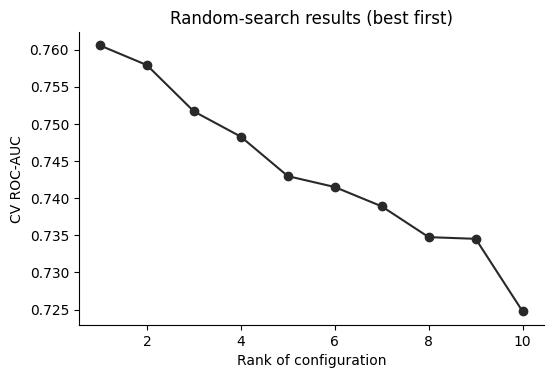

ROC-AUC  baseline: 0.8208   tuned: 0.8244
Best k for KNN: 31


,k,cv_auc
0,3,0.591430
1,5,0.645314
2,7,0.652324
3,11,0.665080
4,15,0.678391
5,21,0.692783
6,31,0.715548


In [14]:
fig = core.plot_tuning(tuning); plt.show()
cb = make_catboost(best_params, cat_cols).fit(Xtr_cb, ytr)       # final model on the full training set
p_cb = cb.predict_proba(Xte_cb)[:, 1]
print(f"ROC-AUC  baseline: {roc_auc_score(yte, p_base):.4f}   tuned: {roc_auc_score(yte, p_cb):.4f}")

# KNN also has a key hyper-parameter (k): choose it by CV as well
best_k, knn_tbl = tune_knn_k(Xtr_num.values, ytr.values)
print("Best k for KNN:", best_k); knn_tbl

## 6. Model evaluation
### 6.1 Manual calculation (required: at least one worked example)
We compute the metrics **by hand from the confusion matrix** and then confirm they equal scikit-learn's.

In [15]:
def confusion_counts(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    return tp, fp, tn, fn


def manual_metrics(y_true, y_pred):
    """Accuracy / precision / recall / F1 computed by hand from the confusion matrix."""
    tp, fp, tn, fn = confusion_counts(y_true, y_pred)
    acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}


def manual_roc_auc(y_true, score):
    """ROC-AUC via the rank (Mann-Whitney U) formula: P(score of a leaver > score of a stayer)."""
    y_true = np.asarray(y_true).astype(int)
    ranks = pd.Series(np.asarray(score)).rank(method="average").values
    n1, n0 = int((y_true == 1).sum()), int((y_true == 0).sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    return (ranks[y_true == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def evaluate(y_true, proba, threshold=0.5):
    m = manual_metrics(y_true, (np.asarray(proba) >= threshold).astype(int))
    m["ROC-AUC"] = manual_roc_auc(y_true, proba)
    return m

In [16]:
pred = (p_cb >= 0.5).astype(int)
tp, fp, tn, fn = core.confusion_counts(yte, pred)
n = tp + tn + fp + fn
print(f"Confusion matrix:  TP={tp}  FP={fp}  TN={tn}  FN={fn}   (n={n})\n")
print(f"Accuracy  = (TP+TN)/n          = ({tp}+{tn})/{n}            = {(tp+tn)/n:.4f}")
print(f"Precision = TP/(TP+FP)         = {tp}/({tp}+{fp})            = {tp/(tp+fp):.4f}")
print(f"Recall    = TP/(TP+FN)         = {tp}/({tp}+{fn})            = {tp/(tp+fn):.4f}")
prec, rec = tp/(tp+fp), tp/(tp+fn)
print(f"F1        = 2PR/(P+R)          = 2*{prec:.3f}*{rec:.3f}/({prec:.3f}+{rec:.3f}) = {2*prec*rec/(prec+rec):.4f}")

# verification against scikit-learn
assert abs((tp+tn)/n - accuracy_score(yte, pred)) < 1e-9
assert abs(prec - precision_score(yte, pred)) < 1e-9
assert abs(rec - recall_score(yte, pred)) < 1e-9
assert abs(core.manual_roc_auc(yte, p_cb) - roc_auc_score(yte, p_cb)) < 1e-9
print("\nManual results match scikit-learn (accuracy, precision, recall, ROC-AUC).")

Confusion matrix:  TP=13  FP=6  TN=237  FN=38   (n=294)

Accuracy  = (TP+TN)/n          = (13+237)/294            = 0.8503
Precision = TP/(TP+FP)         = 13/(13+6)            = 0.6842
Recall    = TP/(TP+FN)         = 13/(13+38)            = 0.2549
F1        = 2PR/(P+R)          = 2*0.684*0.255/(0.684+0.255) = 0.3714

Manual results match scikit-learn (accuracy, precision, recall, ROC-AUC).


**What the numbers mean for HR.** *Recall* = share of real leavers we catch. *Precision* = share of flagged employees who really would leave. A missed leaver (FN) usually costs more than an unnecessary retention conversation (FP), so recall matters.

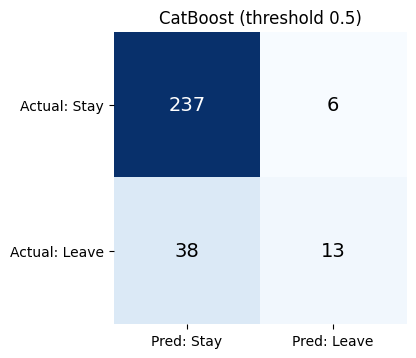

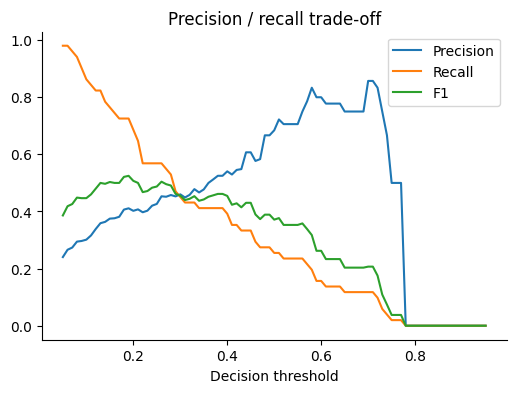

Threshold that maximises F1 on the test set: 0.19 (F1 = 0.525). In practice HR chooses the threshold from the cost of a miss vs. a false alarm.


In [17]:
fig = core.plot_confusion(yte, pred, "CatBoost (threshold 0.5)"); plt.show()
fig = core.plot_threshold_curve(yte, p_cb); plt.show()
thr, f1_at = best_f1_threshold(yte, p_cb)
print(f"Threshold that maximises F1 on the test set: {thr:.2f} (F1 = {f1_at:.3f}). "
      "In practice HR chooses the threshold from the cost of a miss vs. a false alarm.")

**Animation - move the decision threshold.** The black line is the cut-off: everyone to its right is flagged as a likely leaver. Watch how recall rises (and precision falls) as the line moves left.

In [18]:
show_anim(core.animate_threshold(yte, p_cb))

## 7. Comparison / analysis
All models use the **same split and the same metrics**. Class weights are used where the model supports them.

In [19]:
table, probas, _ = compare_models(Xtr_num, ytr, Xte_num, yte, p_cb, knn_k=best_k)
table.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.854,0.633,0.373,0.469,0.845
Manual GBM (scratch),0.840,0.643,0.176,0.277,0.840
Logistic Regression,0.765,0.408,0.784,0.537,0.830
CatBoost (tuned),0.850,0.684,0.255,0.371,0.824
KNN (k=31),0.827,0.000,0.000,0.000,0.780


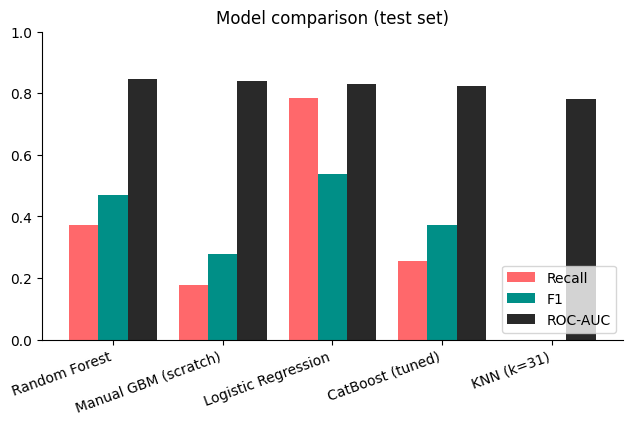

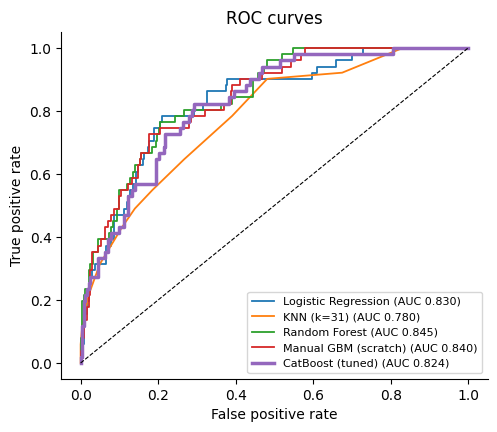

Best ROC-AUC : Random Forest   (0.845)
Best recall  : Logistic Regression   (0.784)
Best F1      : Logistic Regression   (0.537)


In [20]:
fig = core.plot_model_comparison(table); plt.show()
fig = core.plot_roc(yte, probas); plt.show()
print(f"Best ROC-AUC : {table['ROC-AUC'].idxmax()}   ({table['ROC-AUC'].max():.3f})")
print(f"Best recall  : {table['Recall'].idxmax()}   ({table['Recall'].max():.3f})")
print(f"Best F1      : {table['F1'].idxmax()}   ({table['F1'].max():.3f})")

**Animations** - the ROC curves drawing themselves, then a bar race of ROC-AUC -> F1 -> Recall for every model.

In [21]:
show_anim(core.animate_roc(yte, probas))
show_anim(core.animate_model_race(table))

## 8. Visualisation (generated from *this* dataset)

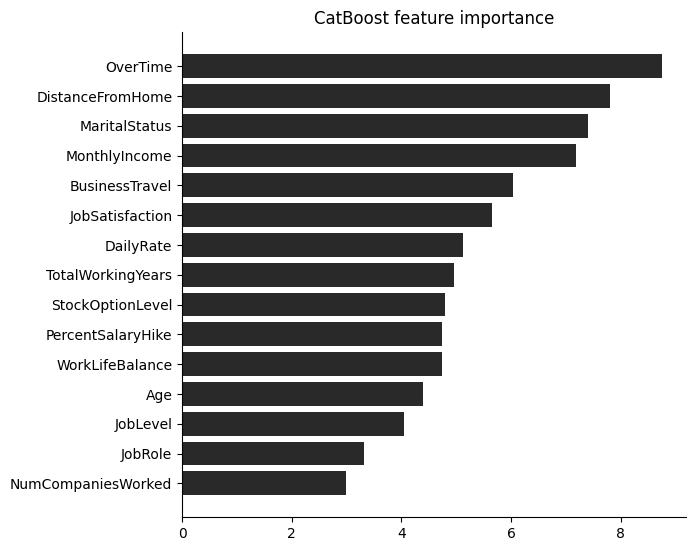

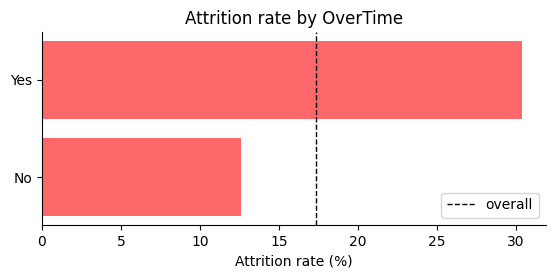

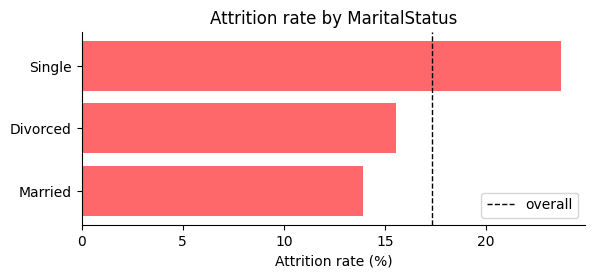

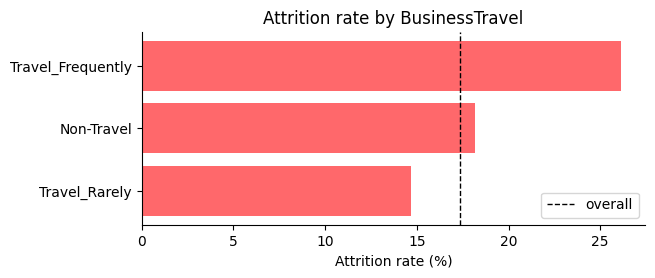

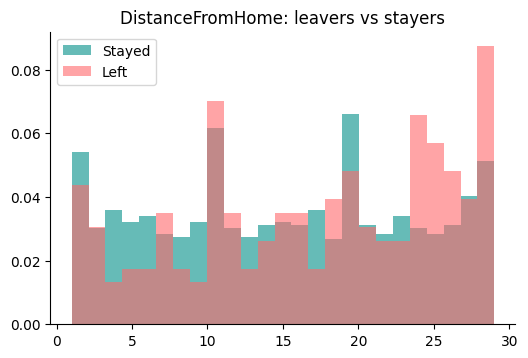

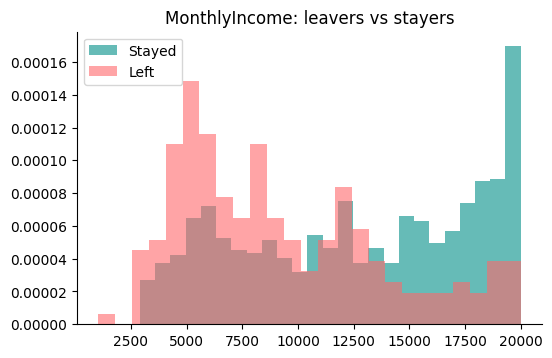

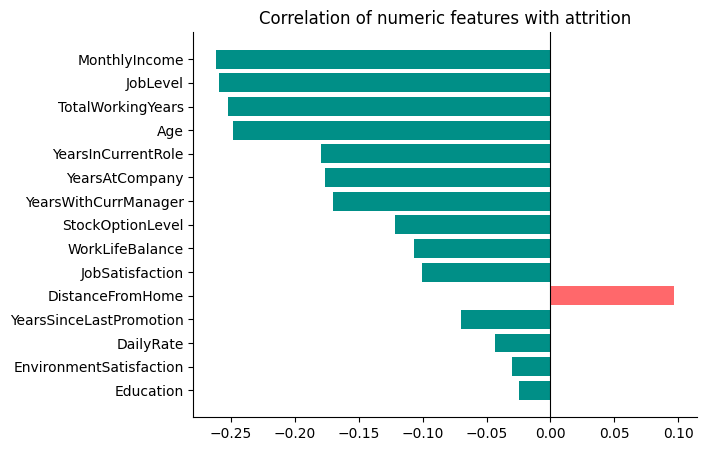

In [22]:
imp = importance_table(cb, Xtr_cb.columns)
fig = core.plot_importance(imp); plt.show()

top_cats = [f for f in imp.feature if f in cat_cols][:3]
for c in top_cats:
    fig = core.plot_rate_by_category(Xtr_cb, ytr, c); plt.show()

top_nums = [f for f in imp.feature if f in pre.num_cols_][:2]
for c in top_nums:
    fig = core.plot_numeric_dist(Xtr_cb, ytr, c); plt.show()

fig = core.plot_corr(Xtr_cb[pre.num_cols_], ytr); plt.show()

show_anim(core.animate_importance(imp))   # animated version of the importance chart

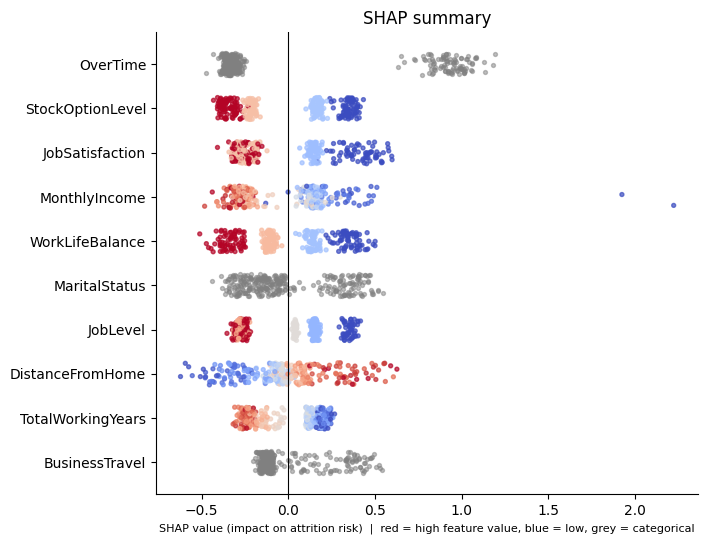

In [23]:
shap_df, _ = catboost_shap(cb, Xte_cb, cat_cols)
fig = core.plot_shap_summary(shap_df, Xte_cb); plt.show()

## 9. Interpretation & discussion
Data-driven findings (computed from the model and the data):

• Overall attrition rate in this data is 17.3%.
• OverTime: attrition is 30.4% for 'Yes' versus 12.6% for 'No'.
• DistanceFromHome: employees who left have a higher average (17.2) than those who stayed (15.0).
• MaritalStatus: attrition is 23.7% for 'Single' versus 13.9% for 'Married'.
• MonthlyIncome: employees who left have a lower average (9,156.1) than those who stayed (12,822.9).
• BusinessTravel: attrition is 26.2% for 'Travel_Frequently' versus 14.7% for 'Travel_Rarely'.
• JobSatisfaction: attrition is 24.1% for '1.0' versus 11.9% for '3.0'.

Highest-risk test employee: predicted attrition probability = 77.4%


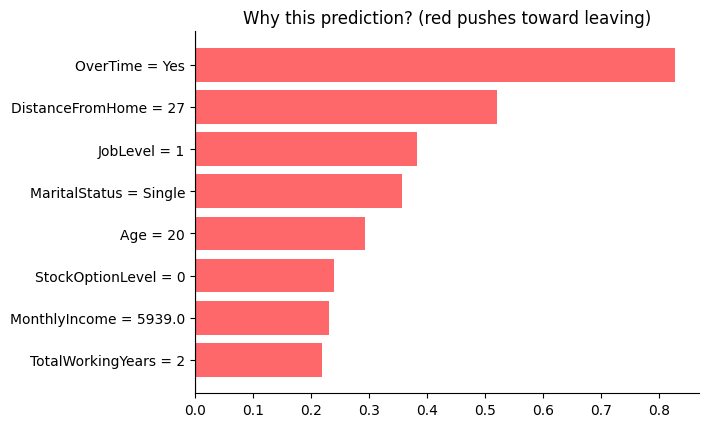

In [24]:
for line in auto_insights(Xtr_cb, ytr, imp):
    print("•", line)

# explain ONE employee: the highest-risk person in the test set
i = int(np.argmax(p_cb))
print(f"\nHighest-risk test employee: predicted attrition probability = {p_cb[i]:.1%}")
fig = core.plot_shap_waterfall(shap_df.iloc[i], Xte_cb.iloc[i]); plt.show()

## 10. Dynamic use - score any new employee file
Save the trained pipeline once, then score *any* uploaded file with the same columns (the target column is optional).
The Streamlit app does exactly this behind an upload button.

In [25]:
bundle = {"pre": pre, "cb": cb, "target": TARGET}
with open("attrition_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

def score_file(path, threshold=0.5):
    new = load_data(path)
    return predict_new(bundle, new, threshold)

# demo: pretend the first 10 test rows are a freshly uploaded file
demo = Xte.head(10).copy()
predict_new(bundle, demo)[["attrition_probability", "risk_level", "predicted_to_leave"]]

,attrition_probability,risk_level,predicted_to_leave
1451,0.2814,Low,0
823,0.1482,Low,0
451,0.1319,Low,0
614,0.1111,Low,0
1054,0.0878,Low,0
239,0.0743,Low,0
125,0.0515,Low,0
234,0.0195,Low,0
1465,0.0187,Low,0
967,0.0150,Low,0


### Run the web app
```
pip install streamlit catboost scikit-learn pandas matplotlib openpyxl
streamlit run app.py
```
Upload any HR CSV/Excel file -> pick the target column -> the whole pipeline above runs automatically, and you can score new employees and download the results.